# Comparaison des 4 pipelines
Agrège les fichiers `results/*.json` produits par les notebooks 01 à 04 (à déposer dans le dossier `results/` du dépôt) et génère les graphiques du rapport dans `figures/`. Ce notebook ne fait aucune inférence : il peut tourner sur n'importe quel environnement.

In [1]:
# Récupération du dépôt : code commun (données, modèle, protocole de mesure)
import os, subprocess, sys
REPO = "https://github.com/Romain-LM-Dev/TP1_deploiement_IA.git"
if os.path.exists("../common.py"):          # exécution locale depuis notebooks/
    os.chdir("..")
elif not os.path.exists("common.py"):       # Google Colab
    if not os.path.exists("TP1_deploiement_IA"):
        subprocess.run(["git", "clone", "-q", REPO], check=True)
    os.chdir("TP1_deploiement_IA")
sys.path.insert(0, os.getcwd())
import common as C
C.env_info()

{'python': '3.14.3',
 'torch': '2.11.0+cpu',
 'torchvision': '0.26.0+cpu',
 'cpu': 'Intel64 Family 6 Model 141 Stepping 1, GenuineIntel',
 'cpu_threads': 8,
 'os_cpu_count': 16}

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
results, metas = C.load_results()
display(pd.DataFrame({k: m["env"] for k, m in metas.items()}))

Résultats chargés : ['01_cpu_openvino', '02_cpu_torchcompile', '03_gpu_tensorrt', '04_gpu_torchcompile']


,01_cpu_openvino,02_cpu_torchcompile,03_gpu_tensorrt,04_gpu_torchcompile
cpu,Intel(R) Xeon(R) CPU @ 2.20GHz,Intel(R) Xeon(R) CPU @ 2.20GHz,Intel(R) Xeon(R) CPU @ 2.00GHz,Intel(R) Xeon(R) CPU @ 2.00GHz
cpu_threads,1,1,1,1
os_cpu_count,2,2,2,2
python,3.13.18,3.13.18,3.13.16,3.13.16
torch,2.11.0+cpu,2.11.0+cpu,2.11.0+cu130,2.11.0+cu130
torchvision,0.26.0+cpu,0.26.0+cpu,0.26.0+cu130,0.26.0+cu130
cuda,NaN,NaN,13.0,13.0
cudnn,NaN,NaN,92700,92700
gpu,NaN,NaN,Tesla T4,Tesla T4


## 1. Débit, temps d'inférence, précision et énergie

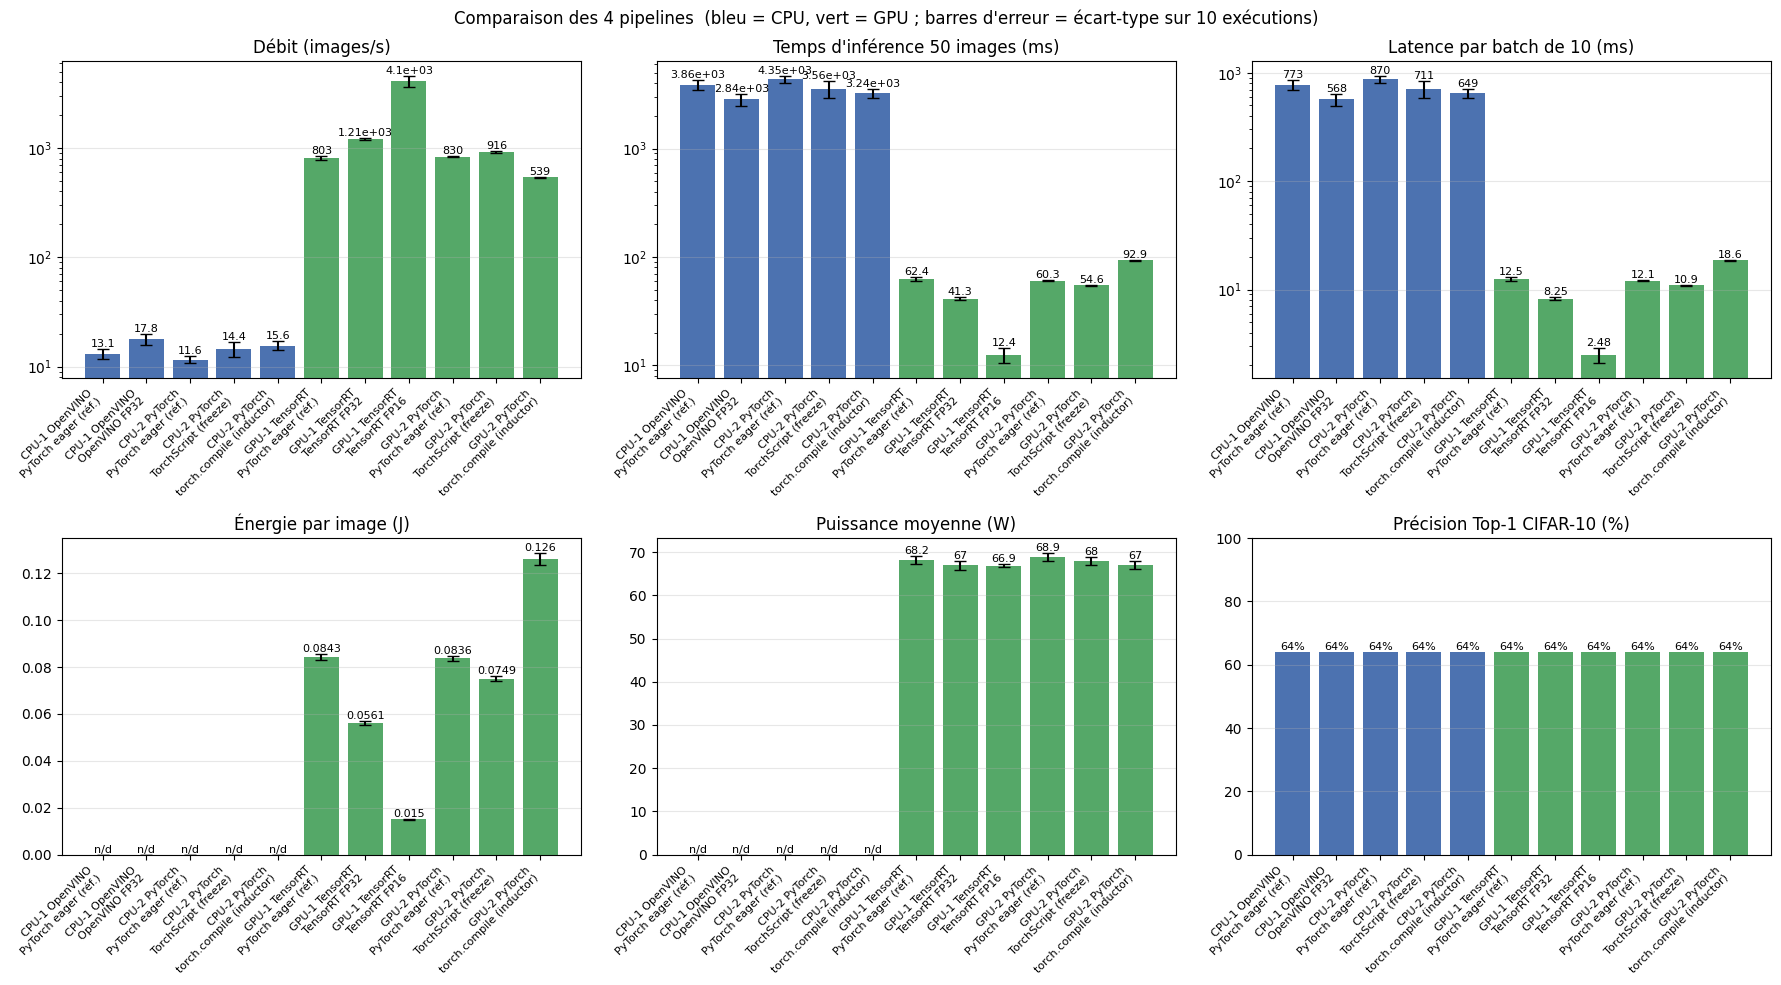

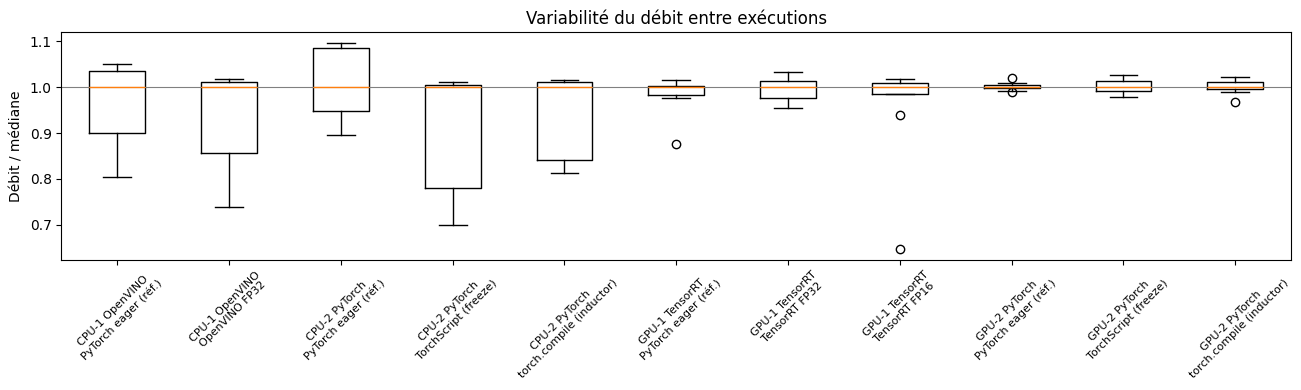

,pipeline,variant,throughput_mean,throughput_std,throughput_min,throughput_max,throughput_cv_pct,total_ms_mean,total_ms_std,total_ms_min,total_ms_max,batch_ms_mean,batch_ms_p95,energy_j_img_mean,energy_j_img_std,power_w_mean,accuracy,agreement_vs_eager,max_abs_diff_vs_eager,first_call_s
0,CPU-1 OpenVINO,PyTorch eager (réf.),13.0581,1.2887,10.9427,14.3028,9.8688,3864.9461,405.1235,3495.8206,4569.2592,772.9869,1109.8750,NaN,NaN,NaN,0.64,1.0,0.0000,0.9132
1,CPU-1 OpenVINO,OpenVINO FP32,17.8267,2.0415,14.0677,19.3934,11.4520,2842.0125,362.1569,2578.1962,3554.2430,568.4007,805.6171,NaN,NaN,NaN,0.64,1.0,0.0000,0.8341
2,CPU-2 PyTorch,PyTorch eager (réf.),11.5529,0.8987,10.2911,12.6144,7.7788,4351.7420,340.9682,3963.7287,4858.5527,870.3459,1229.2552,NaN,NaN,NaN,0.64,1.0,0.0000,1.4118
3,CPU-2 PyTorch,TorchScript (freeze),14.4410,2.2907,11.0628,15.9851,15.8625,3555.0145,649.0610,3127.9179,4519.6671,711.0000,1023.2007,NaN,NaN,NaN,0.64,1.0,0.0000,0.6713
4,CPU-2 PyTorch,torch.compile (inductor),15.5544,1.5020,13.4565,16.8180,9.6567,3242.9432,327.0068,2973.0034,3715.6829,648.5866,934.3206,NaN,NaN,NaN,0.64,1.0,0.0000,24.4722
5,GPU-1 TensorRT,PyTorch eager (réf.),802.7605,33.2969,712.3689,826.7281,4.1478,62.3912,2.8434,60.4794,70.1884,12.4764,14.0087,0.0843,0.0014,68.1669,0.64,1.0,0.0000,0.0180
6,GPU-1 TensorRT,TensorRT FP32,1212.2818,30.5221,1163.2287,1256.5255,2.5177,41.2682,1.0447,39.7923,42.9838,8.2517,8.7244,0.0561,0.0007,66.9554,0.64,1.0,0.0000,0.0059
7,GPU-1 TensorRT,TensorRT FP16,4095.4353,480.4942,2755.3504,4340.6881,11.7324,12.4226,2.0299,11.5189,18.1465,2.4832,3.6270,0.0150,0.0001,66.8737,0.64,1.0,0.0646,0.0038
8,GPU-2 PyTorch,PyTorch eager (réf.),829.6055,7.0977,820.1458,844.4190,0.8555,60.2736,0.5129,59.2123,60.9648,12.0533,12.3356,0.0836,0.0010,68.8939,0.64,1.0,0.0000,3.0481
9,GPU-2 PyTorch,TorchScript (freeze),915.8903,13.6450,893.5670,938.7224,1.4898,54.6026,0.8125,53.2639,55.9555,10.9190,11.3694,0.0749,0.0010,67.9706,0.64,1.0,0.0001,0.3307


In [3]:
df = C.plot_summary(results, "Comparaison des 4 pipelines", "figures/05_comparaison.png")
display(df[C.TABLE_COLS].round(4))
os.makedirs("results", exist_ok=True)
df[C.TABLE_COLS].to_csv("results/synthese.csv", index=False)

## 2. Accélération par rapport à PyTorch eager
Chaque notebook a mesuré sa propre référence *eager* sur la même machine et dans la même session. Le rapport débit / débit eager neutralise donc les écarts de matériel entre sessions Colab.

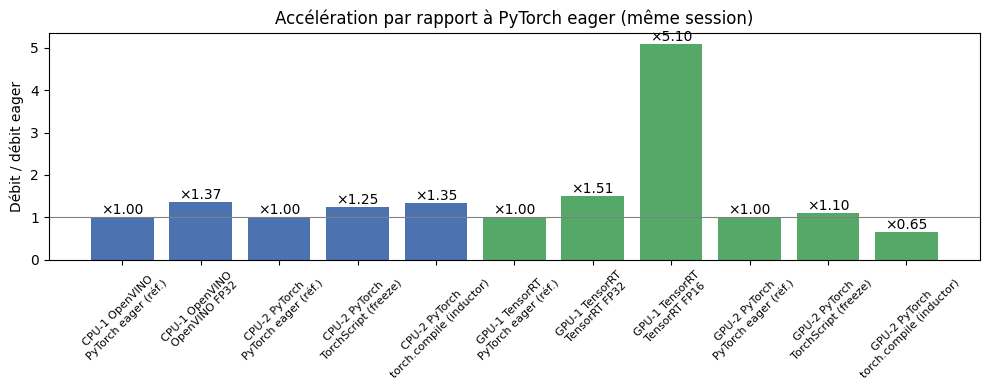

In [4]:
df["speedup"] = df.throughput_mean / df.groupby("pipeline").throughput_mean.transform("first")
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(df.pipeline + "\n" + df.variant, df.speedup, color=["#4C72B0" if d == "cpu" else "#55A868" for d in df.device])
ax.axhline(1, color="grey", lw=.8)
for i, v in enumerate(df.speedup):
    ax.text(i, v, f"×{v:.2f}", ha="center", va="bottom")
ax.set_ylabel("Débit / débit eager")
ax.set_title("Accélération par rapport à PyTorch eager (même session)")
ax.tick_params(axis="x", labelrotation=45, labelsize=8)
fig.tight_layout(); fig.savefig("figures/05_speedup.png", dpi=130); plt.show()

## 3. Cohérence des prédictions entre pipelines
Taux d'accord des classes prédites (Top-1 ImageNet, plus strict que les 10 classes CIFAR) entre toutes les variantes. 100 % partout = les optimisations ne changent aucune prédiction.

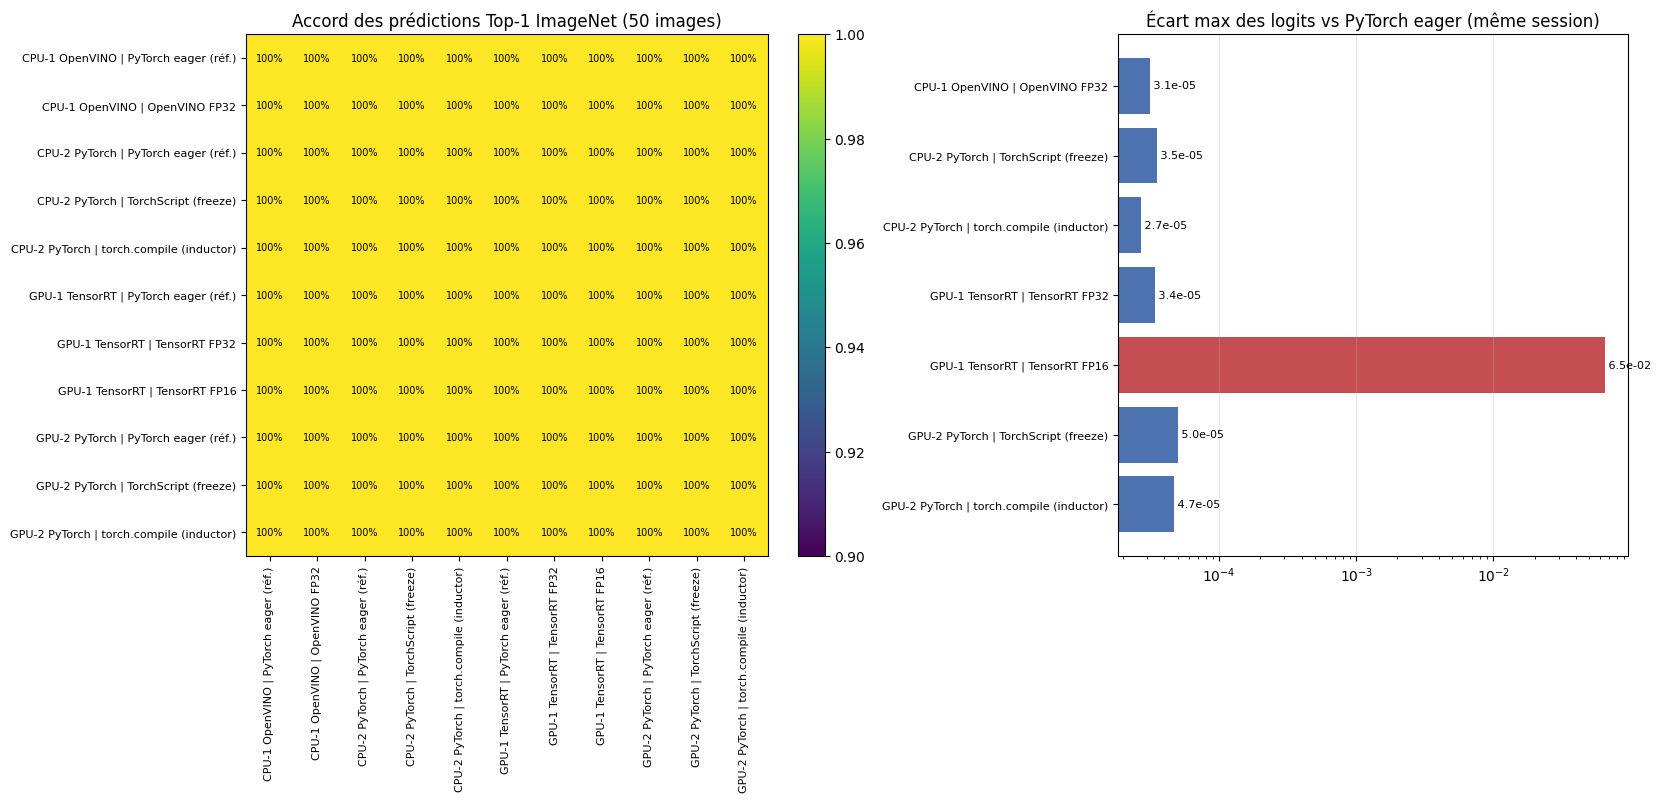

Images dont la prédiction CIFAR diffère selon la variante : []


In [5]:
labels = [f"{r['pipeline']} | {r['variant']}" for r in results]
P = np.array([r["imagenet_top1"] for r in results])
A = (P[:, None, :] == P[None, :, :]).mean(-1)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1.2, 1]})
im = ax.imshow(A, vmin=min(.9, A.min()), vmax=1, cmap="viridis")
ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
for i in range(len(A)):
    for j in range(len(A)):
        ax.text(j, i, f"{A[i, j]:.0%}", ha="center", va="center", fontsize=7, color="w" if A[i, j] < .97 else "k")
fig.colorbar(im, ax=ax, fraction=.046)
ax.set_title("Accord des prédictions Top-1 ImageNet (50 images)")
# Un accord de 100 % peut cacher des écarts numériques : on les montre à part.
opt = [r for r in results if "agreement_vs_eager" in r]
d = [r["max_abs_diff_vs_eager"] for r in opt]
ax2.barh(range(len(opt)), d, color=["#C44E52" if "FP16" in r["variant"] else "#4C72B0" for r in opt])
ax2.set_yticks(range(len(opt)), [f"{r['pipeline']} | {r['variant']}" for r in opt], fontsize=8)
ax2.set_xscale("log"); ax2.invert_yaxis(); ax2.grid(axis="x", alpha=.3)
for i, v in enumerate(d):
    ax2.text(v, i, f" {v:.1e}", va="center", fontsize=8)
ax2.set_title("Écart max des logits vs PyTorch eager (même session)")
fig.tight_layout(); fig.savefig("figures/05_accord_predictions.png", dpi=130); plt.show()
cifar = np.array([r["cifar_pred"] for r in results])
print("Images dont la prédiction CIFAR diffère selon la variante :", np.where((cifar != cifar[0]).any(0))[0].tolist())

## 4. Détail par image (prédiction de la référence vs vérité terrain)

In [6]:
y = np.array(C.load_data()[1])
pd.DataFrame({"vérité": [C.CIFAR_CLASSES[i] for i in y],
              "prédiction": [C.CIFAR_CLASSES[i] for i in cifar[0]],
              "correct": cifar[0] == y}).groupby("vérité").correct.agg(["sum", "count"])

,sum,count
vérité,,
airplane,2,5
automobile,0,3
bird,1,2
cat,1,3
deer,1,5
dog,7,7
frog,6,9
horse,2,4
ship,4,4
